In [1]:
import numpy as np

rng = np.random.default_rng(15)

def dense_forward(x, W, b):
    return x @ W + b

def dense_backward_batch(x, W, dy):
    dW = x.T @ dy
    db = np.array(dy.sum(axis=0))
    dx = dy @ W.T
    return dx, dW, db

def relu(h):
    return np.maximum(0, h)

def batch_normlize(Z):
    Z_norm = np.zeros_like(Z, dtype=float)
    max = np.zeros(Z.shape[0])
    for i in range(Z.shape[0]):
        max[i] = np.max(Z[i])
        Z_norm[i] = Z[i] - np.max(Z[i])
    return Z_norm, max

def batch_softmax(Z):
    Z_norm, max = batch_normlize(Z)
    res = np.zeros_like(Z_norm, dtype=float)
    for i in range(res.shape[0]):
        sum = np.sum(np.exp(Z_norm[i]))
        for j in range(res.shape[1]):
            res[i,j] = np.exp(Z_norm[i,j])/sum
    return res

def label_2_onehot(P, label):
    Y = np.zeros_like(P, dtype=float)
    for i in range(len(label)):
        Y[i, label[i]] = 1.0
    return Y

def batch_ce_grad(P, y):
    return (P - label_2_onehot(P, y))/P.shape[0]

def batch_logsumeps(Z):
    Z_norm, max = batch_normlize(Z)
    lse = np.zeros(Z.shape[0])
    for i in range(Z_norm.shape[0]):
        ln = np.log(sum(np.exp(Z_norm[i])))
        lse[i] = ln + max[i]
    return lse

def batch_neg_log_probs(Z):
    lse = batch_logsumeps(Z)
    neg_log_probs = np.zeros_like(Z, dtype=float)
    for i in range(neg_log_probs.shape[0]):
        for j in range(neg_log_probs.shape[1]):
            neg_log_probs[i,j] = lse[i] - Z[i,j]
    return neg_log_probs

def batch_loss(neg_log_probs, y):
    ave_loss = np.zeros(neg_log_probs.shape[0])
    for i in range(neg_log_probs.shape[0]):
        ave_loss[i] = neg_log_probs[i][y[i]]
    ave = np.sum(ave_loss) / neg_log_probs.shape[0]
    return ave_loss, ave

x1 = rng.standard_normal([6,4])

W1 = rng.normal(0,0.1,[4,5])
b1 = np.zeros([5,])
W2 = rng.normal(0,0.1,[5,3])
b2 = np.zeros([3,])

Z1 = dense_forward(x1, W1, b1)
A1 = relu(Z1); x2 = A1
Z2 = dense_forward(x2, W2, b2)
P = batch_softmax(Z2)
y_idx = np.array([0,1,2,0,1,2])
neg_log_probs = batch_neg_log_probs(Z2)
losses, mean_loss = batch_loss(neg_log_probs, y_idx)

print(x1.shape,W1.shape,Z1.shape,A1.shape,W2.shape,Z2.shape,P.shape)
print("逐行概率和：", np.sum(P, axis=1))
print("概率和最大残差：", np.max(np.abs(np.sum(P, axis=1) - 1.0)))
print("逐样本损失：", losses)
print("平均损失：", mean_loss)

(6, 4) (4, 5) (6, 5) (6, 5) (5, 3) (6, 3) (6, 3)
逐行概率和： [1. 1. 1. 1. 1. 1.]
概率和最大残差： 1.1102230246251565e-16
逐样本损失： [1.08236039 1.09523483 1.12928169 1.09361293 1.1057905  1.10228527]
平均损失： 1.1014276036122765


In [2]:
# 两层 MLP + Softmax/CE：一次完整反向传播与结构验收
tol = 1e-12
W1_before, b1_before = W1.copy(), b1.copy()
W2_before, b2_before = W2.copy(), b2.copy()

dZ2 = (P - label_2_onehot(P,y_idx))/P.shape[0]
dA1, dW2, db2 = dense_backward_batch(A1, W2, dZ2)
dZ1 = dA1 * (Z1 > 0)
dX, dW1, db1 = dense_backward_batch(x1, W1, dZ1)

# 1. 梯度形状
actual_shapes = (dZ2.shape, dA1.shape, dW2.shape, db2.shape,
                 dZ1.shape, dX.shape, dW1.shape, db1.shape)
expected_shapes = ((6,3), (6,5), (5,3), (3,),
                   (6,5), (6,4), (4,5), (5,))
shape_pass = actual_shapes == expected_shapes

# 2. Softmax+CE 对 logits 的梯度结构
dZ2_row_sums = np.sum(dZ2, axis=1)
dZ2_row_sum_max_residual = np.max(np.abs(dZ2_row_sums))
row_sum_pass = dZ2_row_sum_max_residual < tol
target_gradients = dZ2[np.arange(P.shape[0]), y_idx]
target_negative_pass = np.all(target_gradients < 0.0)
non_target_mask = np.ones_like(dZ2, dtype=bool)
non_target_mask[np.arange(P.shape[0]), y_idx] = False
non_target_gradients = dZ2[non_target_mask]
non_target_positive_pass = np.all(non_target_gradients > 0.0)

# 3. ReLU 门：关闭位置梯度为 0，开启位置完整放行 dA1
closed_gradients = dZ1[Z1 <= 0.0]
closed_max_abs = 0.0 if closed_gradients.size == 0 else np.max(np.abs(closed_gradients))
relu_closed_pass = closed_max_abs < tol
active_residuals = np.abs(dZ1[Z1 > 0.0] - dA1[Z1 > 0.0])
active_max_residual = 0.0 if active_residuals.size == 0 else np.max(active_residuals)
relu_active_pass = active_max_residual < tol

# 4. 梯度有限、非零，且反向计算没有修改参数
gradient_arrays = (dZ2, dA1, dW2, db2, dZ1, dX, dW1, db1)
finite_pass = all(np.all(np.isfinite(g)) for g in gradient_arrays)
dW1_norm = np.linalg.norm(dW1)
dW2_norm = np.linalg.norm(dW2)
nonzero_pass = dW1_norm > 0.0 and dW2_norm > 0.0
parameters_unchanged_pass = (
    np.array_equal(W1, W1_before)
    and np.array_equal(b1, b1_before)
    and np.array_equal(W2, W2_before)
    and np.array_equal(b2, b2_before)
)

all_pass = (
    shape_pass and row_sum_pass
    and target_negative_pass and non_target_positive_pass
    and relu_closed_pass and relu_active_pass
    and finite_pass and nonzero_pass and parameters_unchanged_pass
)

print("梯度形状实测：", actual_shapes)
print("梯度形状理论：", expected_shapes, "PASS" if shape_pass else "FAIL")
print("dZ2 每行梯度和：", dZ2_row_sums)
print("dZ2 行和最大绝对残差：", dZ2_row_sum_max_residual, "PASS" if row_sum_pass else "FAIL")
print("真实类梯度：", target_gradients, "PASS" if target_negative_pass else "FAIL")
print("非真实类梯度：", non_target_gradients, "PASS" if non_target_positive_pass else "FAIL")
print("ReLU 关闭位置最大绝对梯度：", closed_max_abs, "PASS" if relu_closed_pass else "FAIL")
print("ReLU 开启位置最大残差：", active_max_residual, "PASS" if relu_active_pass else "FAIL")
print("dW1 范数：", dW1_norm, "；dW2 范数：", dW2_norm, "PASS" if nonzero_pass else "FAIL")
print("所有梯度有限：", finite_pass, "PASS" if finite_pass else "FAIL")
print("反向未修改参数：", parameters_unchanged_pass, "PASS" if parameters_unchanged_pass else "FAIL")
print("总验收：", "PASS" if all_pass else "FAIL")

梯度形状实测： ((6, 3), (6, 5), (5, 3), (3,), (6, 5), (6, 4), (4, 5), (5,))
梯度形状理论： ((6, 3), (6, 5), (5, 3), (3,), (6, 5), (6, 4), (4, 5), (5,)) PASS
dZ2 每行梯度和： [ 0.00000000e+00 -1.38777878e-17  0.00000000e+00  1.38777878e-17
 -6.93889390e-18  0.00000000e+00]
dZ2 行和最大绝对残差： 1.3877787807814457e-17 PASS
真实类梯度： [-0.11020085 -0.11092316 -0.1127891  -0.11083267 -0.11150847 -0.11131479] PASS
非真实类梯度： [0.05651091 0.05368994 0.05577117 0.05515198 0.05742442 0.05536469
 0.05528768 0.055545   0.0563076  0.05520088 0.05498104 0.05633376] PASS
ReLU 关闭位置最大绝对梯度： 0.0 PASS
ReLU 开启位置最大残差： 0.0 PASS
dW1 范数： 0.09561932423427401 ；dW2 范数： 0.04404579709843668 PASS
所有梯度有限： True PASS
反向未修改参数： True PASS
总验收： PASS


In [3]:
# 一次 SGD 参数更新：从新参数重新前向，验证同一 batch 的 CE loss 下降
lr = 0.1
update_tol = 1e-15

W1_after, b1_after = W1_before - lr*dW1, b1_before - lr*db1
W2_after, b2_after = W2_before - lr*dW2, b2_before - lr*db2

# 必须使用新参数重新跑完整前向，不能复用旧的 Z1/A1/Z2/P
Z1_after = dense_forward(x1, W1_after, b1_after)
A1_after = relu(Z1_after)
Z2_after = dense_forward(A1_after, W2_after, b2_after)
P_after = batch_softmax(Z2_after)
losses_after, mean_loss_after = batch_loss(batch_neg_log_probs(Z2_after), y_idx)

# 1. 参数变化必须与 -lr*gradient 一致
update_residual = max(
    np.max(np.abs((W1_after - W1_before) + lr*dW1)),
    np.max(np.abs((b1_after - b1_before) + lr*db1)),
    np.max(np.abs((W2_after - W2_before) + lr*dW2)),
    np.max(np.abs((b2_after - b2_before) + lr*db2)),
)
update_equation_pass = update_residual < update_tol
parameter_delta_norms = (
    np.linalg.norm(W1_after - W1_before),
    np.linalg.norm(b1_after - b1_before),
    np.linalg.norm(W2_after - W2_before),
    np.linalg.norm(b2_after - b2_before),
)
all_parameters_moved_pass = all(delta > 0.0 for delta in parameter_delta_norms)
descent_dot = (
    np.sum((W1_after - W1_before)*dW1)
    + np.sum((b1_after - b1_before)*db1)
    + np.sum((W2_after - W2_before)*dW2)
    + np.sum((b2_after - b2_before)*db2)
)
descent_direction_pass = descent_dot < 0.0

# 2. 新前向仍是合法概率，并且同一 batch 的损失下降
probability_row_sum_residual = np.max(np.abs(np.sum(P_after, axis=1) - 1.0))
probability_pass = probability_row_sum_residual < 1e-12
loss_decrease = mean_loss - mean_loss_after
loss_decrease_pass = loss_decrease > 0.0
finite_after_pass = all(
    np.all(np.isfinite(value))
    for value in (W1_after, b1_after, W2_after, b2_after, P_after, losses_after)
) and np.isfinite(mean_loss_after)

all_update_pass = (
    update_equation_pass and all_parameters_moved_pass
    and descent_direction_pass and probability_pass
    and loss_decrease_pass and finite_after_pass
)

print("更新前平均损失：", mean_loss)
print("更新后平均损失：", mean_loss_after)
print("损失下降量：", loss_decrease, "PASS" if loss_decrease_pass else "FAIL")
print("更新公式最大绝对残差：", update_residual, "PASS" if update_equation_pass else "FAIL")
print("四组参数变化范数：", parameter_delta_norms, "PASS" if all_parameters_moved_pass else "FAIL")
print("参数位移与梯度内积：", descent_dot, "PASS" if descent_direction_pass else "FAIL")
print("更新后概率和最大残差：", probability_row_sum_residual, "PASS" if probability_pass else "FAIL")
print("更新后数值全部有限：", finite_after_pass, "PASS" if finite_after_pass else "FAIL")
print("总验收：", "PASS" if all_update_pass else "FAIL")

更新前平均损失： 1.1014276036122765
更新后平均损失： 1.1001671941349858
损失下降量： 0.0012604094772907803 PASS
更新公式最大绝对残差： 1.2576745200831851e-17 PASS
四组参数变化范数： (np.float64(0.009561932423427401), np.float64(0.003917762852335621), np.float64(0.004404579709843664), np.float64(0.0005782521188951518)) PASS
参数位移与梯度内积： -0.001265141153707064 PASS
更新后概率和最大残差： 2.220446049250313e-16 PASS
更新后数值全部有限： True PASS
总验收： PASS


In [4]:
# 单一可信前向：训练和监控共用同一条计算路径
def classifier_forward(x, y_idx, W1, b1, W2, b2):
    Z1 = dense_forward(x, W1, b1)
    A1 = relu(Z1)
    Z2 = dense_forward(A1, W2, b2)
    P = batch_softmax(Z2)
    losses, mean_loss = batch_loss(batch_neg_log_probs(Z2), y_idx)
    return Z1, A1, Z2, P, losses, mean_loss

def classify_train(x, y_idx, W1, b1, W2, b2, epochs, lr, log_every=10):
    # 在副本上训练，避免函数悄悄改写传入的原始参数
    W1, b1 = W1.copy(), b1.copy()
    W2, b2 = W2.copy(), b2.copy()
    loss_history = []
    accuracy_history = []

    for epoch in range(epochs):
        Z1, A1, Z2, P, losses, mean_loss = classifier_forward(
            x, y_idx, W1, b1, W2, b2
        )
        accuracy = np.mean(np.argmax(P, axis=1) == y_idx)
        loss_history.append(mean_loss)
        accuracy_history.append(accuracy)

        dZ2 = batch_ce_grad(P, y_idx)
        dA1, dW2, db2 = dense_backward_batch(A1, W2, dZ2)
        dZ1 = dA1 * (Z1 > 0.0)
        _, dW1, db1 = dense_backward_batch(x, W1, dZ1)

        W1 -= lr*dW1
        b1 -= lr*db1
        W2 -= lr*dW2
        b2 -= lr*db2

        if epoch % log_every == 0 or epoch == epochs - 1:
            print(f"epoch {epoch:3d}: loss={mean_loss:.9f}, accuracy={accuracy:.3f}")

    # 循环内记录的是每次更新前的结果；这里单独计算最后一次更新后的结果
    _, _, _, P_final, _, final_loss = classifier_forward(
        x, y_idx, W1, b1, W2, b2
    )
    final_accuracy = np.mean(np.argmax(P_final, axis=1) == y_idx)
    loss_history.append(final_loss)
    accuracy_history.append(final_accuracy)
    print(f"final    : loss={final_loss:.9f}, accuracy={final_accuracy:.3f}")

    return (
        W1, b1, W2, b2,
        np.array(loss_history), np.array(accuracy_history), P_final
    )

epochs = 30
train_lr = 0.1
W1_train, b1_train, W2_train, b2_train, loss_history, accuracy_history, P_final = classify_train(
    x1, y_idx, W1_before, b1_before, W2_before, b2_before,
    epochs=epochs, lr=train_lr, log_every=5
)

print("loss：", loss_history[0], "→", loss_history[-1])
print("accuracy：", accuracy_history[0], "→", accuracy_history[-1])

epoch   0: loss=1.101427604, accuracy=0.167
epoch   5: loss=1.095172801, accuracy=0.667
epoch  10: loss=1.090166182, accuracy=0.500
epoch  15: loss=1.085092560, accuracy=0.667
epoch  20: loss=1.079685888, accuracy=0.833
epoch  25: loss=1.073227681, accuracy=0.833
epoch  29: loss=1.066718765, accuracy=0.833
final    : loss=1.065121968, accuracy=0.833
loss： 1.1014276036122765 → 1.0651219677114
accuracy： 0.16666666666666666 → 0.8333333333333334


图像头： (2051, 60000, 28, 28) (2051, 10000, 28, 28)
标签头： (2049, 60000) (2049, 10000)
X_train / y_train： (60000, 784) (60000,)
X_test / y_test： (10000, 784) (10000,)
训练标签分布： [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
IDX 文件头 PASS
训练形状 PASS
测试形状 PASS
样本标签对齐 PASS
像素范围 PASS
标签范围 PASS
数值全部有限 PASS
数据导入总验收： PASS


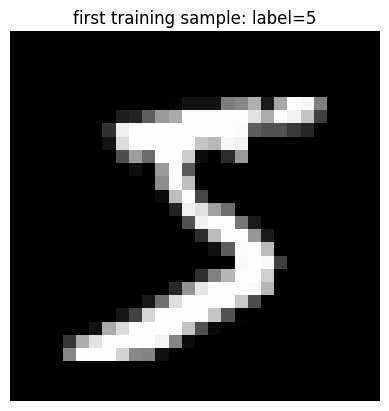

In [5]:
import gzip
import struct
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt

# 压缩文件的固定字节数：先防止半成品下载，再解析 IDX 内容。
SIZES = {
    'train-images-idx3-ubyte.gz': 9912422,
    'train-labels-idx1-ubyte.gz': 28881,
    't10k-images-idx3-ubyte.gz': 1648877,
    't10k-labels-idx1-ubyte.gz': 4542,
}
MNIST_URL = 'https://ossci-datasets.s3.amazonaws.com/mnist'

def find_repo_root():
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'AGENTS.md').exists() and (candidate / 'week04').exists():
            return candidate
    raise FileNotFoundError('找不到仓库根目录：请从 Ai 仓库或其子目录运行 Notebook')

def fetch_mnist_file(base, name):
    path = base / name
    expected_size = SIZES[name]
    if path.exists() and path.stat().st_size == expected_size:
        return path

    # 只处理已知的 MNIST 目标文件；残件不允许直接冒充完整文件。
    if path.exists():
        path.unlink()
    tmp = path.with_name(path.name + '.part')
    urllib.request.urlretrieve(f'{MNIST_URL}/{name}', tmp)
    actual_size = tmp.stat().st_size
    if actual_size != expected_size:
        raise ValueError(f'{name} 下载不完整：{actual_size} != {expected_size}')
    tmp.replace(path)
    return path

def load_idx(path):
    path = Path(path)
    with gzip.open(path, 'rb') as f:
        magic_raw = f.read(4)
        if len(magic_raw) != 4:
            raise ValueError(f'{path.name} 缺少 IDX magic number')
        magic = struct.unpack('>I', magic_raw)[0]

        if magic == 2051:  # 图像：数量、行数、列数
            count, rows, cols = struct.unpack('>III', f.read(12))
            shape = (count, rows, cols)
        elif magic == 2049:  # 标签：数量
            count = struct.unpack('>I', f.read(4))[0]
            shape = (count,)
        else:
            raise ValueError(f'{path.name} magic number 异常：{magic}')

        data = np.frombuffer(f.read(), dtype=np.uint8)

    expected_values = int(np.prod(shape))
    if data.size != expected_values:
        raise ValueError(f'{path.name} 内容长度异常：{data.size} != {expected_values}')
    return data.reshape(shape).copy(), (magic, *shape)

repo_root = find_repo_root()
base = repo_root / 'data' / 'MNIST' / 'raw'
base.mkdir(parents=True, exist_ok=True)
paths = {name: fetch_mnist_file(base, name) for name in SIZES}

train_images, train_images_header = load_idx(paths['train-images-idx3-ubyte.gz'])
y_train, train_labels_header = load_idx(paths['train-labels-idx1-ubyte.gz'])
test_images, test_images_header = load_idx(paths['t10k-images-idx3-ubyte.gz'])
y_test, test_labels_header = load_idx(paths['t10k-labels-idx1-ubyte.gz'])

# MLP 每行接收一张展平图像；float32 足够且比 float64 节省一半内存。
X_train = train_images.reshape(60000, 28*28).astype(np.float32) / 255.0
X_test = test_images.reshape(10000, 28*28).astype(np.float32) / 255.0

expected_headers = (
    (2051, 60000, 28, 28), (2049, 60000),
    (2051, 10000, 28, 28), (2049, 10000),
)
actual_headers = (
    train_images_header, train_labels_header,
    test_images_header, test_labels_header,
)
checks = {
    'IDX 文件头': actual_headers == expected_headers,
    '训练形状': X_train.shape == (60000, 784) and y_train.shape == (60000,),
    '测试形状': X_test.shape == (10000, 784) and y_test.shape == (10000,),
    '样本标签对齐': len(X_train) == len(y_train) and len(X_test) == len(y_test),
    '像素范围': (X_train.min() == 0.0 and X_train.max() == 1.0
                 and X_test.min() == 0.0 and X_test.max() == 1.0),
    '标签范围': (y_train.min() == 0 and y_train.max() == 9
                 and y_test.min() == 0 and y_test.max() == 9),
    '数值全部有限': np.isfinite(X_train).all() and np.isfinite(X_test).all(),
}

print('图像头：', train_images_header, test_images_header)
print('标签头：', train_labels_header, test_labels_header)
print('X_train / y_train：', X_train.shape, y_train.shape)
print('X_test / y_test：', X_test.shape, y_test.shape)
print('训练标签分布：', np.bincount(y_train))
for name, passed in checks.items():
    print(name, 'PASS' if passed else 'FAIL')
print('数据导入总验收：', 'PASS' if all(checks.values()) else 'FAIL')

plt.imshow(X_train[0].reshape(28, 28), cmap='gray')
plt.title(f'first training sample: label={y_train[0]}')
plt.axis('off')
plt.show()

In [6]:
# MNIST mini-batch：每个 epoch 打乱一次，所有样本恰好使用一次
def make_batches(X, y, batch_size, rng):
    if len(X) != len(y):
        raise ValueError(f'X 与 y 数量不一致：{len(X)} != {len(y)}')
    if batch_size <= 0:
        raise ValueError('batch_size 必须为正整数')

    indices = rng.permutation(len(X))
    for start in range(0, len(X), batch_size):
        selected = indices[start:start + batch_size]
        yield X[selected], y[selected]

def evaluate_classifier(X, y, W1, b1, W2, b2, batch_size=1024):
    total_loss = 0.0
    total_correct = 0

    for start in range(0, len(X), batch_size):
        tx = X[start:start + batch_size]
        tb = y[start:start + batch_size]
        _, _, _, P, losses, _ = classifier_forward(
            tx, tb, W1, b1, W2, b2
        )
        total_loss += np.sum(losses)
        total_correct += np.sum(np.argmax(P, axis=1) == tb)

    return total_loss / len(X), total_correct / len(X)

def train_classifier_minibatch(
    X_train, y_train, X_test, y_test,
    W1, b1, W2, b2,
    epochs, batch_size, lr, rng
):
    # 训练副本与初始参数分离，便于重复实验。
    W1, b1 = W1.copy(), b1.copy()
    W2, b2 = W2.copy(), b2.copy()
    history = {
        'online_train_loss': [],
        'online_train_accuracy': [],
        'test_loss': [],
        'test_accuracy': [],
    }

    for epoch in range(1, epochs + 1):
        loss_sum = 0.0
        correct_sum = 0
        seen = 0
        batch_count = 0

        for tx, tb in make_batches(X_train, y_train, batch_size, rng):
            Z1, A1, Z2, P, losses, _ = classifier_forward(
                tx, tb, W1, b1, W2, b2
            )

            # 这些是本批更新前的在线训练指标。
            loss_sum += np.sum(losses)
            correct_sum += np.sum(np.argmax(P, axis=1) == tb)
            seen += len(tx)
            batch_count += 1

            dZ2 = batch_ce_grad(P, tb)
            dA1, dW2, db2 = dense_backward_batch(A1, W2, dZ2)
            dZ1 = dA1 * (Z1 > 0.0)
            _, dW1, db1 = dense_backward_batch(tx, W1, dZ1)

            W1 -= lr*dW1
            b1 -= lr*db1
            W2 -= lr*dW2
            b2 -= lr*db2

        online_train_loss = loss_sum / seen
        online_train_accuracy = correct_sum / seen
        test_loss, test_accuracy = evaluate_classifier(
            X_test, y_test, W1, b1, W2, b2
        )
        history['online_train_loss'].append(online_train_loss)
        history['online_train_accuracy'].append(online_train_accuracy)
        history['test_loss'].append(test_loss)
        history['test_accuracy'].append(test_accuracy)

        expected_batches = (len(X_train) + batch_size - 1) // batch_size
        if seen != len(X_train) or batch_count != expected_batches:
            raise RuntimeError(
                f'epoch 覆盖异常：seen={seen}, batches={batch_count}, '
                f'expected={len(X_train)}/{expected_batches}'
            )

        print(
            f'epoch {epoch:2d}/{epochs}: '
            f'train_loss={online_train_loss:.6f}, '
            f'train_acc={online_train_accuracy:.4f}, '
            f'test_loss={test_loss:.6f}, '
            f'test_acc={test_accuracy:.4f}'
        )

    final_train_loss, final_train_accuracy = evaluate_classifier(
        X_train, y_train, W1, b1, W2, b2
    )
    final_test_loss, final_test_accuracy = evaluate_classifier(
        X_test, y_test, W1, b1, W2, b2
    )
    print(
        'final：',
        f'train_loss={final_train_loss:.6f}, ',
        f'train_acc={final_train_accuracy:.4f}, ',
        f'test_loss={final_test_loss:.6f}, ',
        f'test_acc={final_test_accuracy:.4f}'
    )

    return W1, b1, W2, b2, history

# 784 → 128 → 10；ReLU 前使用 He 初始化。
input_dim = X_train.shape[1]
hidden_dim = 128
class_count = int(np.max(y_train)) + 1
init_rng = np.random.default_rng(15)
batch_rng = np.random.default_rng(16)

W1_mnist = init_rng.normal(
    0.0, np.sqrt(2.0 / input_dim), (input_dim, hidden_dim)
)
b1_mnist = np.zeros(hidden_dim)
W2_mnist = init_rng.normal(
    0.0, np.sqrt(2.0 / hidden_dim), (hidden_dim, class_count)
)
b2_mnist = np.zeros(class_count)

mnist_epochs = 8
mnist_batch_size = 64
mnist_lr = 0.1

W1_mnist_trained, b1_mnist_trained, W2_mnist_trained, b2_mnist_trained, mnist_history = (
    train_classifier_minibatch(
        X_train, y_train, X_test, y_test,
        W1_mnist, b1_mnist, W2_mnist, b2_mnist,
        epochs=mnist_epochs,
        batch_size=mnist_batch_size,
        lr=mnist_lr,
        rng=batch_rng,
    )
)

epoch  1/8: train_loss=0.360423, train_acc=0.9001, test_loss=0.212080, test_acc=0.9385
epoch  2/8: train_loss=0.190496, train_acc=0.9454, test_loss=0.158278, test_acc=0.9552
epoch  3/8: train_loss=0.143397, train_acc=0.9590, test_loss=0.123643, test_acc=0.9657
epoch  4/8: train_loss=0.116089, train_acc=0.9673, test_loss=0.107693, test_acc=0.9691
epoch  5/8: train_loss=0.098519, train_acc=0.9718, test_loss=0.097001, test_acc=0.9718
epoch  6/8: train_loss=0.085433, train_acc=0.9756, test_loss=0.090161, test_acc=0.9732
epoch  7/8: train_loss=0.074528, train_acc=0.9789, test_loss=0.088518, test_acc=0.9745
epoch  8/8: train_loss=0.066662, train_acc=0.9813, test_loss=0.089886, test_acc=0.9738
final： train_loss=0.067702,  train_acc=0.9801,  test_loss=0.089886,  test_acc=0.9738


In [7]:
pred_parts = []
batch_size = 1024

for start in range(0, len(X_test), batch_size):
    tx = X_test[start:start + batch_size]
    tb = y_test[start:start + batch_size]

    _, _, _, P, _, _ = classifier_forward(
        tx, tb,
        W1_mnist_trained, b1_mnist_trained,
        W2_mnist_trained, b2_mnist_trained
    )

    batch_pred = P.argmax(axis=1)
    pred_parts.append(batch_pred)

y_pred = np.concatenate((pred_parts))

loss_eval, accuracy_eval = evaluate_classifier(
    X_test,
    y_test,
    W1_mnist_trained,
    b1_mnist_trained,
    W2_mnist_trained,
    b2_mnist_trained,
)

accuracy_from_pred = np.mean(y_pred == y_test)
accuracy_from_history = mnist_history["test_accuracy"][-1]

print("y_pred 计算：", accuracy_from_pred)
print("evaluate_classifier 重算：", accuracy_eval)
print("训练历史末值：", accuracy_from_history)

print(
    "预测 vs 独立评估残差：",
    abs(accuracy_from_pred - accuracy_eval)
)
print(
    "当前参数 vs 历史记录残差：",
    abs(accuracy_eval - accuracy_from_history)
)

y_pred 计算： 0.9738
evaluate_classifier 重算： 0.9738
训练历史末值： 0.9738
预测 vs 独立评估残差： 0.0
当前参数 vs 历史记录残差： 0.0


猜测C[3,5] < C[5,3]

In [8]:
C = np.zeros((10, 10), dtype=int)

for true_label, predicted_label in zip(y_test, y_pred):
    C[true_label, predicted_label] += 1

row_sum_residual = np.max(
    np.abs(C.sum(axis=1) - np.bincount(y_test, minlength=10))
)

accuracy_from_C = C.trace() / C.sum()
accuracy_residual = abs(accuracy_from_C - accuracy_eval)

print("矩阵形状：", C.shape)
print("样本总数：", C.sum())
print("行和最大残差：", row_sum_residual)
print("混淆矩阵准确率：", accuracy_from_C)
print("准确率对拍残差：", accuracy_residual)

confusion_pass = (
    C.shape == (10, 10)
    and C.sum() == 10000
    and row_sum_residual == 0
    and accuracy_residual < 1e-12
)

print("混淆矩阵验收：", "PASS" if confusion_pass else "FAIL")

print("C[3,5] =", C[3,5])
print("C[5,3] =", C[5,3])

矩阵形状： (10, 10)
样本总数： 10000
行和最大残差： 0
混淆矩阵准确率： 0.9738
准确率对拍残差： 0.0
混淆矩阵验收： PASS
C[3,5] = 2
C[5,3] = 9


In [9]:
C_offdiag = C.copy()

# 把 C_offdiag 的对角线清零，但不能修改原始 C
np.fill_diagonal(C_offdiag, 0)

flat_index = np.unravel_index(np.argmax(C_offdiag), C_offdiag.shape)
true_label, predicted_label = flat_index[0], flat_index[1]
max_count = C_offdiag[true_label, predicted_label]

print("最大混淆方向：", true_label, "→", predicted_label)
print("错误数量：", max_count)
print("原始矩阵仍保持准确率：", C.trace() / C.sum())

最大混淆方向： 8 → 3
错误数量： 25
原始矩阵仍保持准确率： 0.9738


第 2、3、5、6 张确实具有明显的“像 3”特征：上半部分偏小或偏右、左右不对称、右侧弯曲更突出。
第 1、4 张接近标准 8，说明错误不能全部归因于字迹含糊，模型的分类边界也存在不足。

该方向错例总数： 25


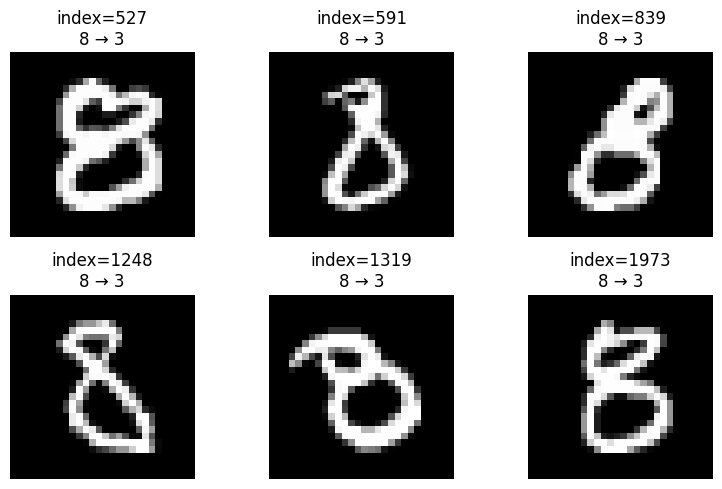

错例选择验收： PASS


In [10]:
wrong_indices = np.where(
    (y_test == 8) & (y_pred == 3)
)[0]

print("该方向错例总数：", len(wrong_indices))

selected_indices = wrong_indices[:6]

fig, axes = plt.subplots(2, 3, figsize=(8, 5))

for ax, index in zip(axes.ravel(), selected_indices):
    ax.imshow(X_test[index].reshape(28, 28), cmap="gray")
    ax.set_title(
        f"index={index}\n"
        f"{y_test[index]} → {y_pred[index]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

example_pass = (
    len(wrong_indices) == C[8, 3] == 25
    and len(selected_indices) == 6
    and np.all(y_test[selected_indices] == 8)
    and np.all(y_pred[selected_indices] == 3)
)

print("错例选择验收：", "PASS" if example_pass else "FAIL")